In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, IFrame, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 170)
RES = ROOT / "results"
def show_png(path, width=620):
    display(Image(filename=str(path), width=width))

# 03 · Model comparison (five model families)
Fit and 5-fold **GroupKFold by trip** cross-validation on the 80 train trips; development comparison on the 10 student_test trips.
Observation-level **Top-1** (per GPS point, highest-scoring candidate vs the reference arc) is the selection metric because it
measures the matching objective directly; macro F1 and log loss describe the candidate rows (positives are a minority class).
Code: `models/train_models.py`; results: `results/model_comparison.csv`.

In [2]:
mc = pd.read_csv(RES / "model_comparison.csv")
cols = ["model","algorithm_family","configuration","cv_top1","cv_top1_std","cv_macro_f1","test_top1","test_macro_f1","test_precision","test_recall","test_log_loss","test_route_continuity","fit_seconds","infer_ms_per_1k_rows"]
display(mc[cols].round(4))

,model,algorithm_family,configuration,cv_top1,cv_top1_std,cv_macro_f1,test_top1,test_macro_f1,test_precision,test_recall,test_log_loss,test_route_continuity,fit_seconds,infer_ms_per_1k_rows
0,hist_gradient_boosting,Boosting,"HistGradientBoosting(max_iter=150, learning_ra...",0.7432,0.1717,0.8889,0.8563,0.9162,0.8743,0.8426,0.1092,0.9358,6.8391,2.1391
1,random_forest,Ensemble (bagging),"RandomForest(n_estimators=60, max_depth=14, mi...",0.7426,0.1715,0.8875,0.8561,0.9151,0.8905,0.8236,0.1104,0.9323,34.1472,1.9737
2,decision_tree,Tree-based,"DecisionTree(max_depth=12, min_samples_leaf=50)",0.7412,0.1716,0.8750,0.8516,0.9147,0.8856,0.8269,0.1130,0.9337,15.0331,0.0910
3,logistic_regression,Linear / probabilistic,StandardScaler + LogisticRegression(C=1.0),0.7308,0.1688,0.8480,0.8416,0.8926,0.8429,0.7941,0.1699,0.9261,1.0016,0.0949
4,gaussian_naive_bayes,Probabilistic (generative),StandardScaler + GaussianNB,0.7169,0.1647,0.7881,0.8193,0.7953,0.5441,0.8880,0.4838,0.9422,0.4415,0.3649


In [3]:
best = mc.sort_values("cv_top1", ascending=False).iloc[0]
print(f"Best by CV Top-1: {best.model} (CV {best.cv_top1:.4f} ± {best.cv_top1_std:.4f}, student_test {best.test_top1:.4f}).")
gap = (mc.cv_top1 - mc.test_top1).round(4)
print("CV minus student_test Top-1 per model (a large positive gap would suggest overfitting):")
print(pd.Series(gap.values, index=mc.model).to_string())

Best by CV Top-1: hist_gradient_boosting (CV 0.7432 ± 0.1717, student_test 0.8563).
CV minus student_test Top-1 per model (a large positive gap would suggest overfitting):
model
hist_gradient_boosting   -0.1131
random_forest            -0.1135
decision_tree            -0.1103
logistic_regression      -0.1109
gaussian_naive_bayes     -0.1024


## Comparison plots

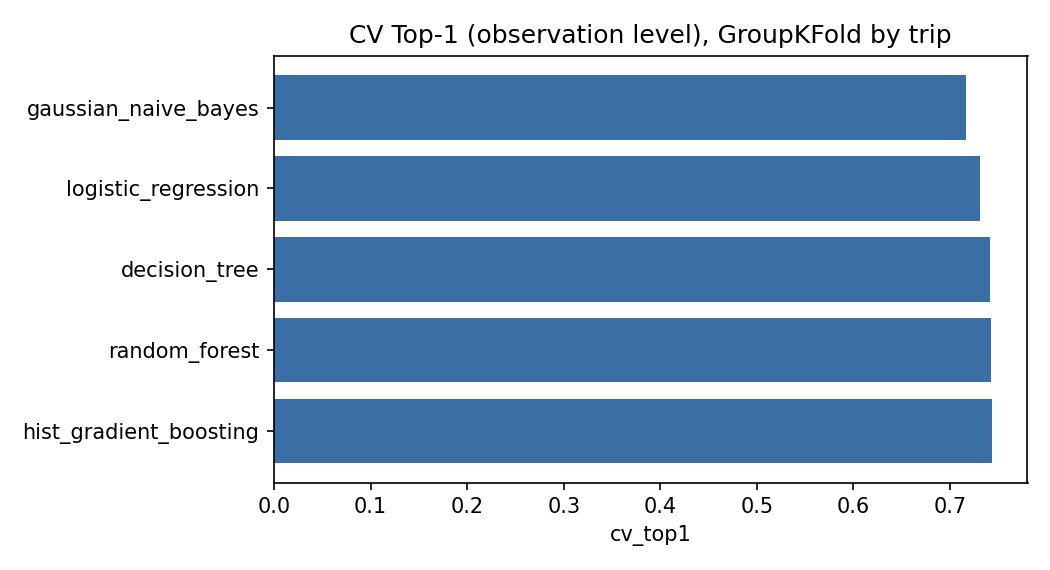

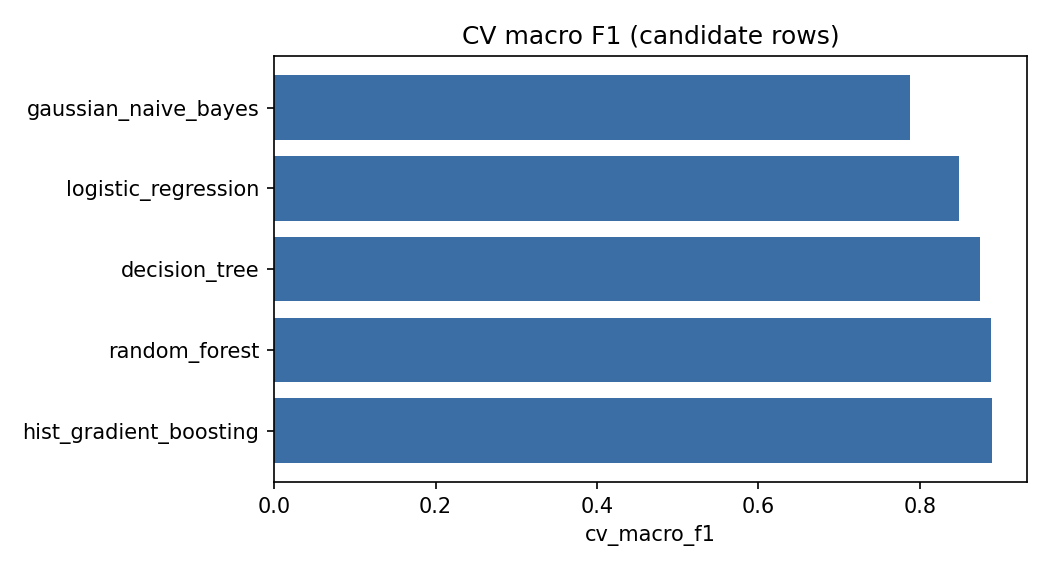

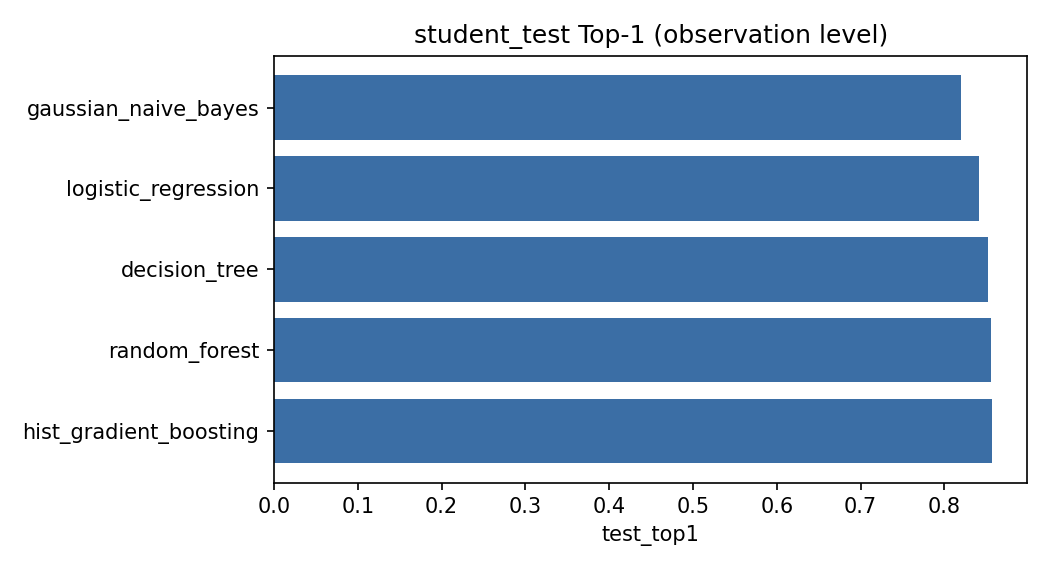

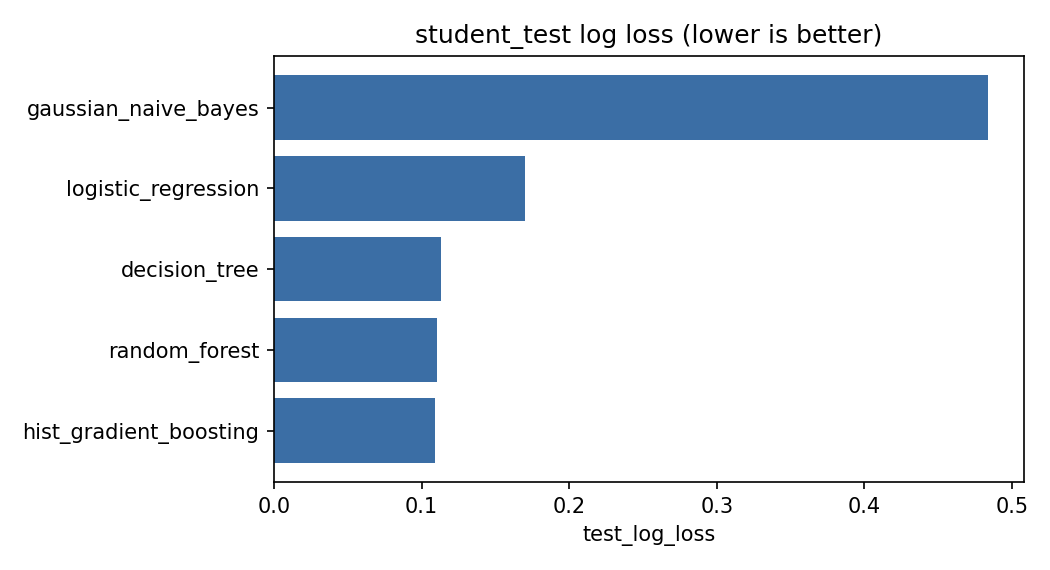

In [4]:
for f in ["model_cv_top1","model_cv_macro_f1","model_student_top1","model_student_log_loss"]:
    show_png(RES / f"figures/{f}.png", 560)

## Confusion matrices and probability quality
Training/validation loss curves are not shown: none of these algorithms (as configured) produces an epoch-wise history, and artificial curves are not drawn.

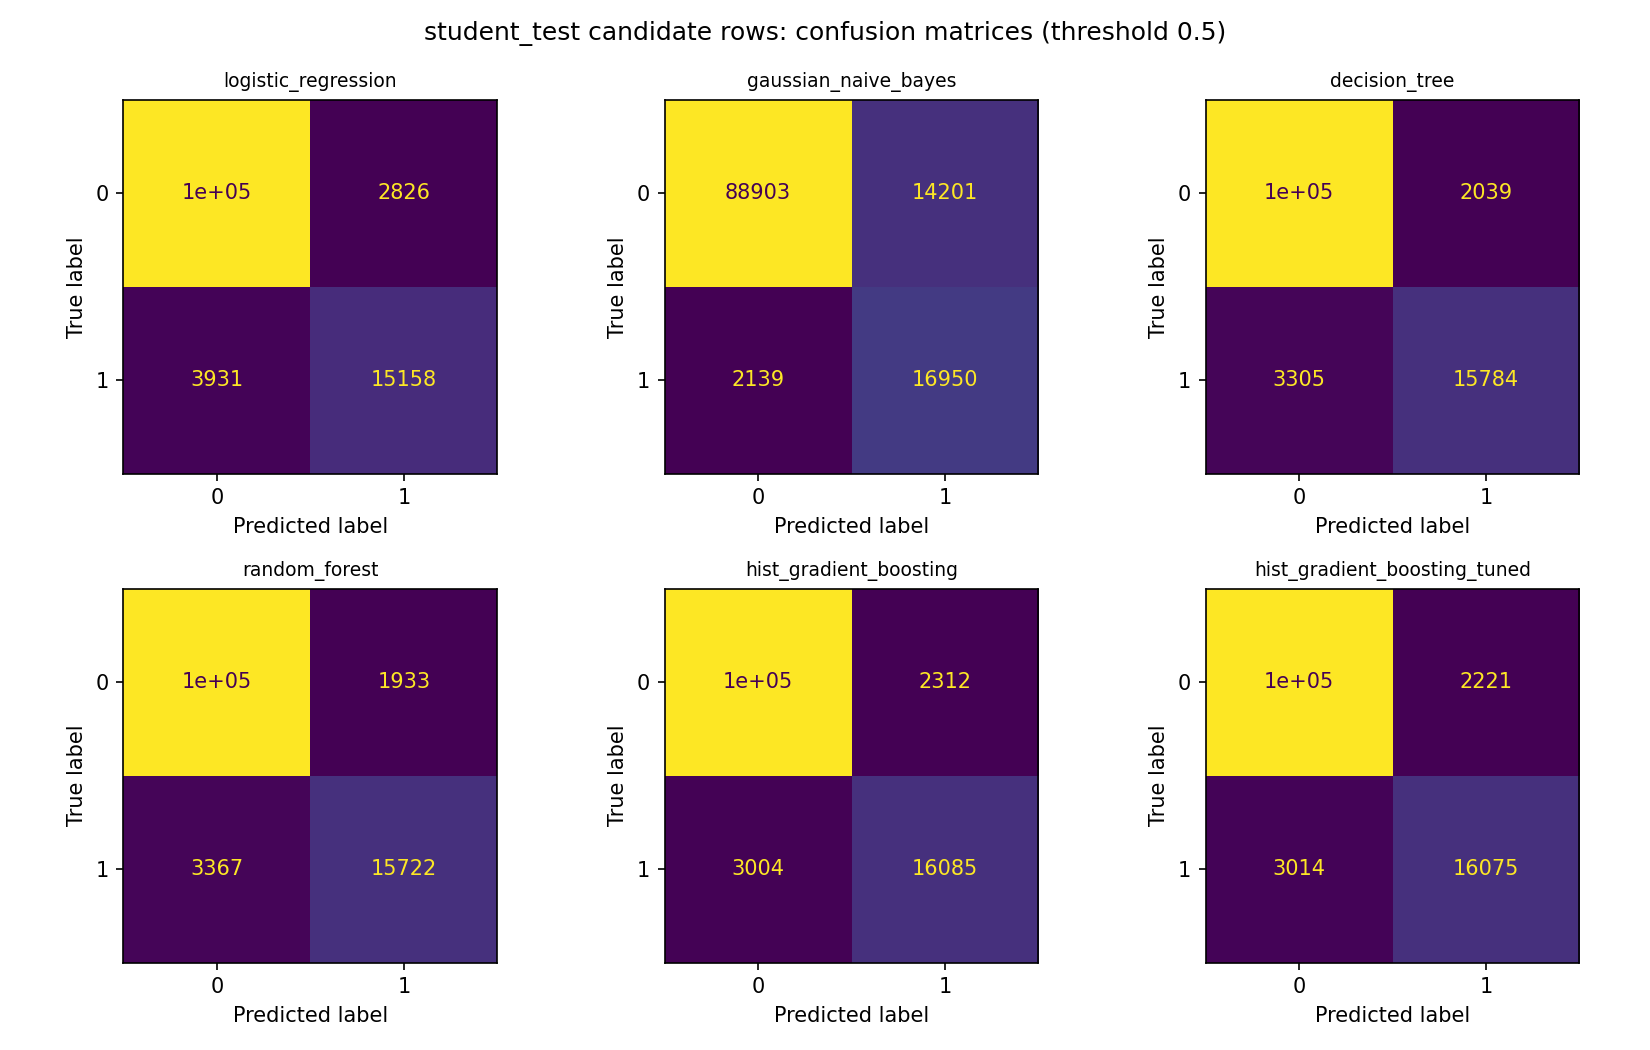

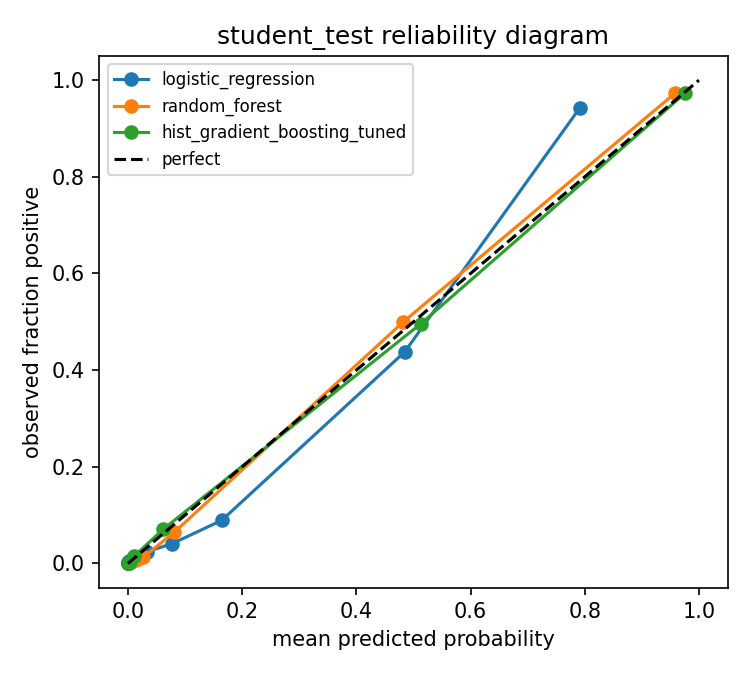

In [5]:
show_png(RES / "figures/model_confusion_all.png", 760)
show_png(RES / "figures/model_calibration.png", 460)

## Does excluding the unreliable-label trips matter?
Some train trips have unreliable reference tails (notebook 01). The same model is fitted on all 80 trips and on the unflagged ones only.

In [6]:
ab = pd.read_csv(RES / "ablation_flagged_trips.csv")
display(ab.round(4))
d = ab.test_top1.max() - ab.test_top1.min()
print(f"student_test Top-1 differs by only {d:.4f} between the two training sets, so the protocol uses all 80 trips (the flagged trips are only reported here).")

,train_set,trips,rows,test_top1,test_macro_f1,test_log_loss,test_route_continuity
0,all 80 train trips,80,1314688,0.8563,0.9162,0.1092,0.9358
1,73 trips (7 flagged excluded),73,932014,0.8564,0.9154,0.1113,0.9335


student_test Top-1 differs by only 0.0000 between the two training sets, so the protocol uses all 80 trips (the flagged trips are only reported here).
